# Analysis: Comparing LLM Iced Classification vs Review-Based Iced Level

This notebook compares:
- **iced_llm**: LLM classification of products as iced (True/False) based on product name and description
- **iced_level**: User-derived iced level from reviews (1-4 scale)

Goal: Validate LLM accuracy and understand patterns in iced product classification

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Load Data

In [2]:
# Load LLM iced classifications
iced_llm_df = pd.read_csv('results/iced_products_v2.csv')
print(f"LLM Iced Products: {len(iced_llm_df)} rows")
print(f"Columns: {iced_llm_df.columns.tolist()}")
print(f"\nSample:")
iced_llm_df.head()

LLM Iced Products: 5449 rows
Columns: ['Site', 'id', 'name', 'site_tag', 'iced_llm', 'llm_justification', 'desc']

Sample:


,Site,id,name,site_tag,iced_llm,llm_justification,desc
0,GETPOP,1761,Lost Mary MT15000 Turbo Acai Berry Storm Ice,lost-mary-mt15000-turbo-acai-berry-storm-ice,True,The product name and description explicitly in...,Highlights \nBattery: 650mAh\nNicotine: 5%\n15...
1,GETPOP,1765,Lost Mary OS5000 Acai Berry Storm Ice,lost-mary-os5000-acai-berry-storm-ice,True,"The product name includes ""Storm Ice"" and the ...",Highlights \nBattery: 650mAh\nNicotine: 5%\n50...
2,GETPOP,1767,Air Bar Diamond Box 20000 Alaskan Mint,air-bar-diamond-box-20000-alaskan-mint-1,False,The product is listed only as 'Alaskan Mint' f...,Highlights \nBattery: 800mAh\nNicotine: 5%\n20...
3,GETPOP,1769,RAZ CA6000 Alaskan Mint,raz-ca6000-alaskan-mint,False,The product name and description only mention ...,Highlights \nBattery: 650mAh\nNicotine: 5%\n60...
4,GETPOP,1771,Hyppe Max Flow Aloe Grape,hyppe-max-flow-aloe-grape,False,The product name and description contain no te...,Highlights \nBattery: 900mAh\nNicotine: 5%\n20...


In [3]:
# Load review-based sentiment data with iced_level
reviews_df = pd.read_csv('results/getpop_sentiment_reviews.csv')
reviews_df = reviews_df[reviews_df['verified']]
print(f"Review Sentiment Data: {len(reviews_df)} rows")
print(f"Columns: {reviews_df.columns.tolist()}")
print(f"\nSample:")
reviews_df.head()

Review Sentiment Data: 2927 rows
Columns: ['Product', 'iced_level', 'sweet_level', 'rating', 'Sentiment', 'Sentiment Score', 'Site', 'Review', 'Product ID', 'Review ID', 'verified']

Sample:


,Product,iced_level,sweet_level,rating,Sentiment,Sentiment Score,Site,Review,Product ID,Review ID,verified
0,raz-ca6000-alaskan-mint,4.0,4.0,1.0,neutral,0.593693,GETPOP,Way too sweet,1769,318,True
1,hyppe-max-flow-aloe-grape,3.0,3.0,5.0,positive,0.617023,GETPOP,Great flavor,1771,10175,True
2,hyppe-max-flow-aloe-grape,NaN,NaN,5.0,neutral,0.397947,GETPOP,Perfect,1771,10174,True
3,hyppe-max-flow-aloe-grape,NaN,4.0,5.0,neutral,0.535714,GETPOP,Wonderful,1771,10173,True
4,hyde-edge-recharge-aloe-grape,2.0,2.0,4.0,neutral,0.538910,GETPOP,Nice smooth flavor,1773,10128,True


In [4]:
# 1. If sweet_level is not null AND iced_level is null -> set iced_level to 0
reviews_df.loc[reviews_df['sweet_level'].notna() & reviews_df['iced_level'].isna(), 'iced_level'] = 0

# 2. If iced_level is not null AND sweet_level is null -> set sweet_level to 0
reviews_df.loc[reviews_df['iced_level'].notna() & reviews_df['sweet_level'].isna(), 'sweet_level'] = 0

In [5]:
reviews_df.head()

,Product,iced_level,sweet_level,rating,Sentiment,Sentiment Score,Site,Review,Product ID,Review ID,verified
0,raz-ca6000-alaskan-mint,4.0,4.0,1.0,neutral,0.593693,GETPOP,Way too sweet,1769,318,True
1,hyppe-max-flow-aloe-grape,3.0,3.0,5.0,positive,0.617023,GETPOP,Great flavor,1771,10175,True
2,hyppe-max-flow-aloe-grape,NaN,NaN,5.0,neutral,0.397947,GETPOP,Perfect,1771,10174,True
3,hyppe-max-flow-aloe-grape,0.0,4.0,5.0,neutral,0.535714,GETPOP,Wonderful,1771,10173,True
4,hyde-edge-recharge-aloe-grape,2.0,2.0,4.0,neutral,0.538910,GETPOP,Nice smooth flavor,1773,10128,True


## 2. Data Preparation & Joining

In [6]:
# Check data types and missing values
print("LLM Data Info:")
print(iced_llm_df[['id', 'iced_llm']].info())
print(f"\nIced_llm value counts:")
print(iced_llm_df['iced_llm'].value_counts(dropna=False))

print("\n" + "="*50 + "\n")

print("Review Data Info:")
print(reviews_df[['Product ID', 'iced_level']].info())
print(f"\nIced_level value counts:")
print(reviews_df['iced_level'].value_counts(dropna=False))

LLM Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 5449 entries, 0 to 5448
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        5449 non-null   int64
 1   iced_llm  5449 non-null   bool 
dtypes: bool(1), int64(1)
memory usage: 48.0 KB
None

Iced_llm value counts:
iced_llm
False    3347
True     2102
Name: count, dtype: int64


Review Data Info:
<class 'pandas.DataFrame'>
Index: 2927 entries, 0 to 2940
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Product ID  2927 non-null   int64  
 1   iced_level  2410 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 68.6 KB
None

Iced_level value counts:
iced_level
0.0    693
4.0    547
2.0    541
NaN    517
3.0    378
1.0    251
Name: count, dtype: int64


In [8]:
# Aggregate iced_level by product (take mean for products with multiple reviews)
product_iced_level = reviews_df.groupby('Product ID').agg({
    'iced_level': ['mean', 'count', 'std'],
    'Product': 'first'
}).reset_index()

product_iced_level.columns = ['Product_ID', 'iced_level_mean', 'review_count', 'iced_level_std', 'product_tag']
print(f"Products with iced_level: {len(product_iced_level)}")
product_iced_level.sort_values(by='review_count', ascending=False).head()

Products with iced_level: 1235


,Product_ID,iced_level_mean,review_count,iced_level_std,product_tag
272,3035,0.714286,21,1.346954,fifty-bar-20k-vanilla-custard
13,1852,3.500000,20,0.760886,hyde-edge-recharge-minty-os
21,1885,2.277778,18,1.274434,hyde-edge-recharge-spearmint
181,2487,1.470588,17,1.504894,raz-ltx-25k-tobacco
281,3054,3.214286,14,0.801784,eb-design-bc5000-miami-mint


In [12]:
# Convert iced_llm to boolean
iced_llm_df['iced_llm'] = iced_llm_df['iced_llm'].astype(str).str.strip().str.lower() == 'true'

# Ensure IDs are the same type
iced_llm_df['id'] = iced_llm_df['id'].astype(str)
product_iced_level['Product_ID'] = product_iced_level['Product_ID'].astype(str)

# Join the datasets
comparison_df = iced_llm_df.merge(
    product_iced_level,
    left_on='id',
    right_on='Product_ID',
    how='inner'
)

print(f"Matched products: {len(comparison_df)}")
print(f"Products with both iced_llm and iced_level: {comparison_df['iced_level_mean'].notna().sum()}")
comparison_df.head()

Matched products: 1235
Products with both iced_llm and iced_level: 1081


,Site,id,name,site_tag,iced_llm,llm_justification,desc,Product_ID,iced_level_mean,review_count,iced_level_std,product_tag
0,GETPOP,1769,RAZ CA6000 Alaskan Mint,raz-ca6000-alaskan-mint,False,The product name and description only mention ...,Highlights \nBattery: 650mAh\nNicotine: 5%\n60...,1769,4.0,1,NaN,raz-ca6000-alaskan-mint
1,GETPOP,1771,Hyppe Max Flow Aloe Grape,hyppe-max-flow-aloe-grape,False,The product name and description contain no te...,Highlights \nBattery: 900mAh\nNicotine: 5%\n20...,1771,1.5,2,2.12132,hyppe-max-flow-aloe-grape
2,GETPOP,1773,Hyde Edge Recharge Aloe Grape,hyde-edge-recharge-aloe-grape,False,The product name and description mention only ...,Highlights \nNicotine: 5%\n3000-3999 puffs\nRe...,1773,2.0,1,NaN,hyde-edge-recharge-aloe-grape
3,GETPOP,1783,Fume Ultra 2500 Apple Candy,fume-ultra-apple-candy,False,The product name and description mention only ...,Highlights \nBattery: 1000mAh\nNicotine: 5%\n2...,1783,2.0,1,NaN,fume-ultra-apple-candy
4,GETPOP,1790,HandShake 15K Pod Apple Gummies,handshake-15k-pod-apple-gummies,False,The product name and description mention only ...,Highlights \nBattery: 300mAh\nNicotine: 5%\n15...,1790,NaN,0,NaN,handshake-15k-pod-apple-gummies


## 3. Overall Statistics

In [13]:
# Filter to products with iced_level data
analysis_df = comparison_df[comparison_df['iced_level_mean'].notna()].copy()
print(f"Products for analysis: {len(analysis_df)}")

# Basic statistics
print("\nLLM Classification:")
print(analysis_df['iced_llm'].value_counts())
print(f"\nPercentage classified as iced: {analysis_df['iced_llm'].mean()*100:.2f}%")

print("\nIced Level Statistics:")
print(analysis_df['iced_level_mean'].describe())

Products for analysis: 1081

LLM Classification:
iced_llm
False    715
True     366
Name: count, dtype: int64

Percentage classified as iced: 33.86%

Iced Level Statistics:
count    1081.000000
mean        1.955373
std         1.372132
min         0.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         4.000000
Name: iced_level_mean, dtype: float64


## 4. Distribution Analysis

/var/folders/r6/bbh6nj696l1_bkjr135f4whj0sdf0t/T/ipykernel_92850/1821896937.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['False (Not Iced)', 'True (Iced)'])


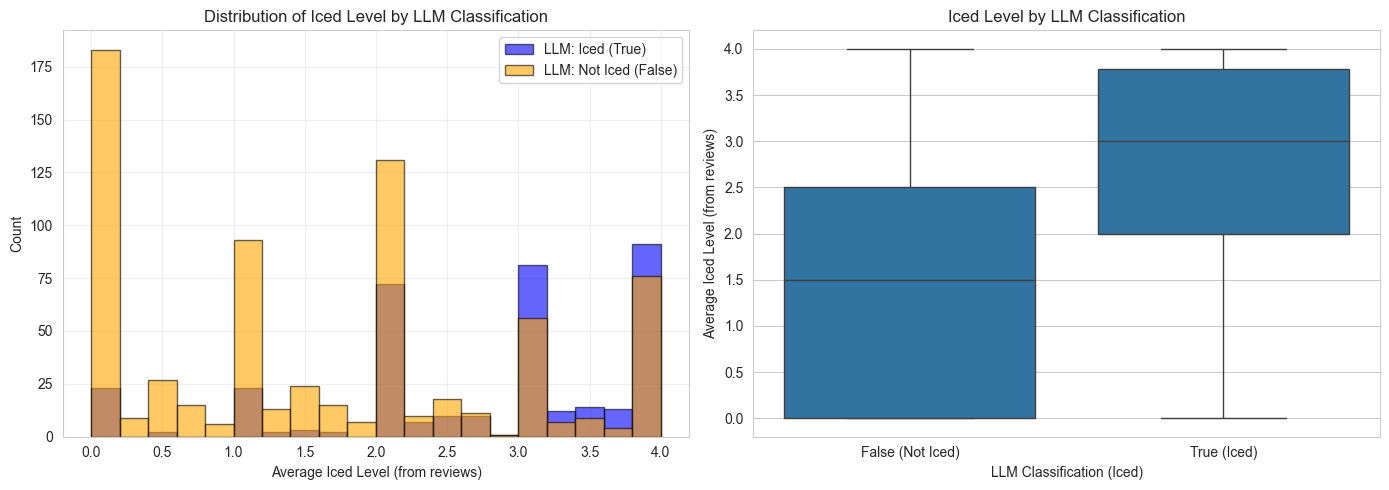

In [14]:
# Distribution of iced_level for LLM True vs False
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(analysis_df[analysis_df['iced_llm'] == True]['iced_level_mean'], 
             bins=20, alpha=0.6, label='LLM: Iced (True)', color='blue', edgecolor='black')
axes[0].hist(analysis_df[analysis_df['iced_llm'] == False]['iced_level_mean'], 
             bins=20, alpha=0.6, label='LLM: Not Iced (False)', color='orange', edgecolor='black')
axes[0].set_xlabel('Average Iced Level (from reviews)')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Iced Level by LLM Classification')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Box plot
sns.boxplot(data=analysis_df, x='iced_llm', y='iced_level_mean', ax=axes[1])
axes[1].set_xlabel('LLM Classification (Iced)')
axes[1].set_ylabel('Average Iced Level (from reviews)')
axes[1].set_title('Iced Level by LLM Classification')
axes[1].set_xticklabels(['False (Not Iced)', 'True (Iced)'])

plt.tight_layout()
plt.savefig('results/iced_llm_vs_level_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Confusion Matrix Analysis

We'll create a binary classification from iced_level:
- iced_level >= 3 → "Iced" (according to reviews)
- iced_level < 3 → "Not Iced"

In [15]:
analysis_df = analysis_df[analysis_df['review_count'] > 2]
analysis_df.shape

(270, 12)

In [16]:
# Create binary label from iced_level
threshold = 1
analysis_df['iced_by_reviews'] = analysis_df['iced_level_mean'] >= threshold

# Confusion matrix
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

cm = confusion_matrix(analysis_df['iced_by_reviews'], analysis_df['iced_llm'])
print(f"Confusion Matrix (threshold={threshold}):")
print(f"                  LLM: Not Iced  |  LLM: Iced")
print(f"Reviews: Not Iced     {cm[0,0]:6d}      |  {cm[0,1]:6d}")
print(f"Reviews: Iced         {cm[1,0]:6d}      |  {cm[1,1]:6d}")

accuracy = accuracy_score(analysis_df['iced_by_reviews'], analysis_df['iced_llm'])
print(f"\nAccuracy: {accuracy*100:.2f}%")

print("\nClassification Report:")
print(classification_report(analysis_df['iced_by_reviews'], analysis_df['iced_llm'], 
                          target_names=['Not Iced', 'Iced']))

Confusion Matrix (threshold=1):
                  LLM: Not Iced  |  LLM: Iced
Reviews: Not Iced         59      |       0
Reviews: Iced            130      |      81

Accuracy: 51.85%

Classification Report:
              precision    recall  f1-score   support

    Not Iced       0.31      1.00      0.48        59
        Iced       1.00      0.38      0.55       211

    accuracy                           0.52       270
   macro avg       0.66      0.69      0.52       270
weighted avg       0.85      0.52      0.54       270



In [17]:
analysis_df['iced_by_reviews'].value_counts()

iced_by_reviews
True     211
False     59
Name: count, dtype: int64

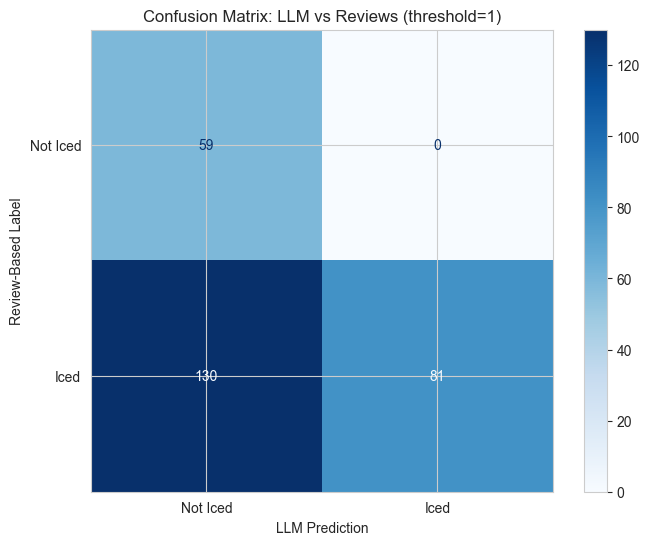

In [18]:
# Visualize confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Iced', 'Iced'])
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title(f'Confusion Matrix: LLM vs Reviews (threshold={threshold})')
ax.set_xlabel('LLM Prediction')
ax.set_ylabel('Review-Based Label')
plt.savefig('results/iced_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Disagreement Analysis

Let's examine cases where LLM and reviews disagree

In [19]:
# False Positives: LLM says iced, but reviews say not iced
false_positives = analysis_df[(analysis_df['iced_llm'] == True) & (analysis_df['iced_by_reviews'] == False)]
print(f"False Positives (LLM says iced, reviews say not): {len(false_positives)}")
print("\nSample False Positives:")
df_fp = (false_positives[['name', 'iced_level_mean', 'review_count', 'llm_justification']].sort_values(by="iced_level_mean", ascending=True))
df_fp.to_csv('results/iced_fp.csv', index=False)

False Positives (LLM says iced, reviews say not): 0

Sample False Positives:


In [24]:
# False Negatives: LLM says not iced, but reviews say iced
false_negatives = analysis_df[(analysis_df['iced_llm'] == False) & (analysis_df['iced_by_reviews'] == True)]
print(f"False Negatives (LLM says not iced, reviews say iced): {len(false_negatives)}")
print("\nSample False Negatives:")
df_fn = (false_negatives[['name', 'iced_level_mean', 'review_count', 'llm_justification']].sort_values(by='iced_level_mean', ascending=False))
df_fn = df_fn[~df_fn['name'].str.contains('mint', case=False, na=False)]
df_fn.to_csv('results/iced_fn.csv', index=False)

df_fn.head(n=20)

False Negatives (LLM says not iced, reviews say iced): 130

Sample False Negatives:


,name,iced_level_mean,review_count,llm_justification
699,Air Bar Nex 6500 Strawberry Yogurt,4.000000,3,The product name and description mention only ...
966,Lost Angel Mate 50K Pod Blackberry B-Pop,4.000000,3,The product description does not contain any m...
310,Air Bar Mini 2000 Clear,4.000000,4,The product name and description contain no me...
258,North Stellar 40K Banana Coconut,3.666667,3,The product name and description only mention ...
63,Geek Bar Pulse 15000 Berry Bliss (Berry Cherry),3.666667,3,The product name and description do not contai...
1015,Foger Switch Pro 30K Pod Mexico Mango,3.400000,5,The product description mentions only the swee...
1126,SMOK Spaceman Nebula 25K Plus Sour Grape BG,3.333333,3,The product name and description mention only ...
413,Oxbar Magic Maze 2 Clear Emerald,3.000000,4,The product name and description do not contai...
944,Cali UL20000 Triple Berry,3.000000,5,The product name and description contain no wo...
129,RAZ LTX 25K Clear,3.000000,3,The product name and description contain no me...


## 7. Threshold Sensitivity Analysis

How does accuracy change with different thresholds?

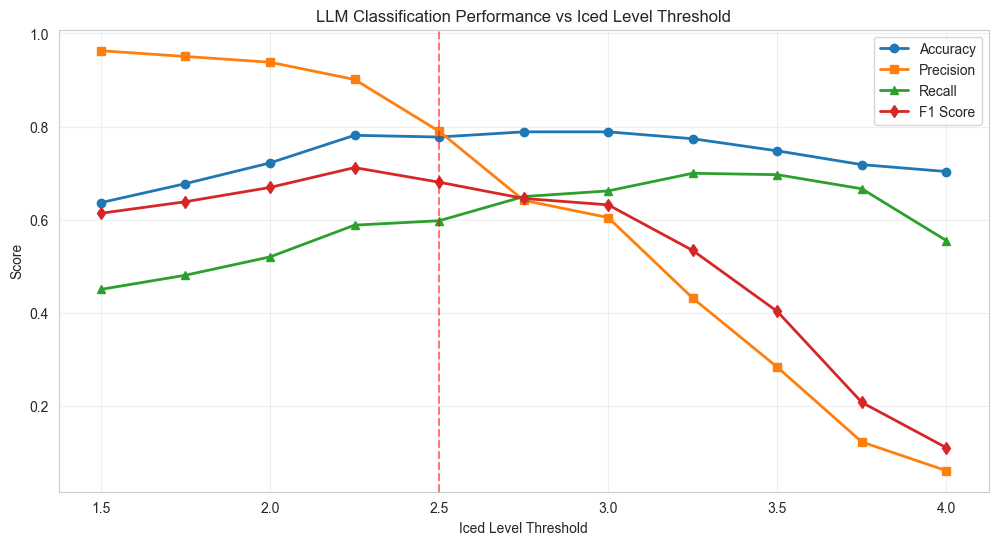


Optimal threshold (max F1): 2.25
F1 Score at optimal: 0.7122
Accuracy at optimal: 0.7815


In [95]:
# Test different thresholds
thresholds = np.arange(1.5, 4.1, 0.25)
accuracies = []
precisions = []
recalls = []
f1_scores = []

from sklearn.metrics import precision_score, recall_score, f1_score

for thresh in thresholds:
    iced_binary = analysis_df['iced_level_mean'] >= thresh
    acc = accuracy_score(iced_binary, analysis_df['iced_llm'])
    prec = precision_score(iced_binary, analysis_df['iced_llm'], zero_division=0)
    rec = recall_score(iced_binary, analysis_df['iced_llm'], zero_division=0)
    f1 = f1_score(iced_binary, analysis_df['iced_llm'], zero_division=0)
    
    accuracies.append(acc)
    precisions.append(prec)
    recalls.append(rec)
    f1_scores.append(f1)

# Plot
plt.figure(figsize=(12, 6))
plt.plot(thresholds, accuracies, marker='o', label='Accuracy', linewidth=2)
plt.plot(thresholds, precisions, marker='s', label='Precision', linewidth=2)
plt.plot(thresholds, recalls, marker='^', label='Recall', linewidth=2)
plt.plot(thresholds, f1_scores, marker='d', label='F1 Score', linewidth=2)
plt.xlabel('Iced Level Threshold')
plt.ylabel('Score')
plt.title('LLM Classification Performance vs Iced Level Threshold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.axvline(x=2.5, color='red', linestyle='--', alpha=0.5, label='Default threshold=2.5')
plt.savefig('results/iced_threshold_sensitivity.png', dpi=300, bbox_inches='tight')
plt.show()

# Find optimal threshold
optimal_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[optimal_idx]
print(f"\nOptimal threshold (max F1): {optimal_threshold}")
print(f"F1 Score at optimal: {f1_scores[optimal_idx]:.4f}")
print(f"Accuracy at optimal: {accuracies[optimal_idx]:.4f}")

## 8. Iced Level Statistics by LLM Classification

In [96]:
# Summary statistics
print("Iced Level Statistics by LLM Classification:\n")
print(analysis_df.groupby('iced_llm')['iced_level_mean'].describe())

# Statistical test
from scipy import stats

iced_true = analysis_df[analysis_df['iced_llm'] == True]['iced_level_mean']
iced_false = analysis_df[analysis_df['iced_llm'] == False]['iced_level_mean']

t_stat, p_value = stats.ttest_ind(iced_true, iced_false)
print(f"\nT-test results:")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4e}")
print(f"Significant difference: {p_value < 0.05}")

Iced Level Statistics by LLM Classification:

          count      mean       std  min       25%  50%       75%  max
iced_llm                                                              
False     189.0  1.561484  1.064450  0.0  0.714286  1.5  2.285714  4.0
True       81.0  2.989354  0.676634  1.0  2.538462  3.0  3.500000  4.0

T-test results:
T-statistic: 11.1401
P-value: 6.1435e-24
Significant difference: True


## 9. Review Count Impact

Does agreement improve with more reviews?

Accuracy by Review Count:
     bin  accuracy  count
0    2-5  0.500000    192
1   6-10  0.571429     56
2  11-50  0.545455     22


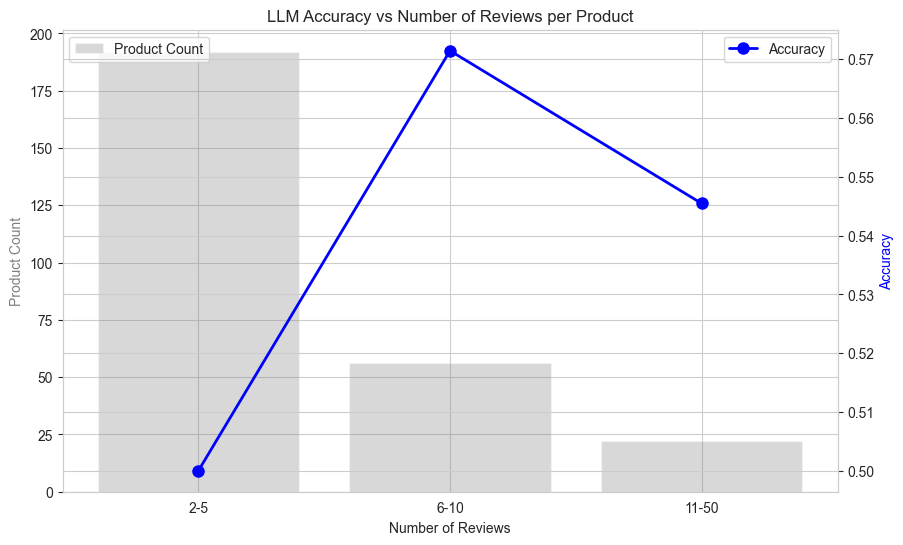

In [97]:
# Analyze by review count bins
analysis_df['review_bin'] = pd.cut(analysis_df['review_count'], 
                                    bins=[0, 1, 5, 10, 50, 1000],
                                    labels=['1', '2-5', '6-10', '11-50', '50+'])

# Calculate accuracy by review count bin
accuracy_by_reviews = []
for bin_label in ['1', '2-5', '6-10', '11-50', '50+']:
    bin_data = analysis_df[analysis_df['review_bin'] == bin_label]
    if len(bin_data) > 0:
        acc = accuracy_score(bin_data['iced_by_reviews'], bin_data['iced_llm'])
        accuracy_by_reviews.append({'bin': bin_label, 'accuracy': acc, 'count': len(bin_data)})

acc_df = pd.DataFrame(accuracy_by_reviews)
print("Accuracy by Review Count:")
print(acc_df)

# Plot
fig, ax1 = plt.subplots(figsize=(10, 6))
ax2 = ax1.twinx()

ax1.bar(acc_df['bin'], acc_df['count'], alpha=0.3, color='gray', label='Product Count')
ax2.plot(acc_df['bin'], acc_df['accuracy'], marker='o', color='blue', linewidth=2, markersize=8, label='Accuracy')

ax1.set_xlabel('Number of Reviews')
ax1.set_ylabel('Product Count', color='gray')
ax2.set_ylabel('Accuracy', color='blue')
ax1.set_title('LLM Accuracy vs Number of Reviews per Product')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')
plt.savefig('results/iced_accuracy_by_review_count.png', dpi=300, bbox_inches='tight')
plt.show()

## 10. Export Results

In [ ]:
# Export comparison data
export_df = analysis_df[[
    'id', 'name', 'site_tag', 'iced_llm', 'llm_justification',
    'iced_level_mean', 'iced_level_std', 'review_count', 
    'iced_by_reviews'
]].copy()

export_df['agreement'] = export_df['iced_llm'] == export_df['iced_by_reviews']

export_df.to_csv('results/iced_llm_vs_reviews_comparison.csv', index=False)
print(f"Exported {len(export_df)} products to results/iced_llm_vs_reviews_comparison.csv")

# Export disagreements for manual review
disagreements = export_df[export_df['agreement'] == False].sort_values('review_count', ascending=False)
disagreements.to_csv('results/iced_disagreements.csv', index=False)
print(f"Exported {len(disagreements)} disagreements to results/iced_disagreements.csv")

Exported 270 products to results/iced_llm_vs_reviews_comparison.csv
Exported 130 disagreements to results/iced_disagreements.csv


: 

## Summary

This analysis compares:
1. **LLM Classification** (iced_llm): Binary classification based on product name/description
2. **Review-Based Level** (iced_level): User-reported iced intensity (1-4 scale)

Key findings will include:
- Overall accuracy and agreement rate
- Distribution differences between LLM True/False classifications
- False positive and false negative patterns
- Optimal threshold for converting iced_level to binary
- Impact of review count on classification reliability